In [3]:
# 1. AŞAMA: Gerekli Kütüphanelerin İçe Aktarılması

# Temel dosya işlemleri ve matematiksel hesaplamalar için
import os
import numpy as np
import pandas as pd

# Röntgen görüntülerini ve başarı grafiklerini ekrana çizdirmek için
import matplotlib.pyplot as plt
import seaborn as sns

# Yapay zeka modelini kurmak ve eğitmek için (Derin Öğrenme Araçları)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Kurulumun başarılı olduğunu test etmek için kısa bir çıktı alalım
print("TensorFlow Versiyonu:", tf.__version__)
print("1. Aşama tamamlandı: Kütüphaneler başarıyla yüklendi!")

TensorFlow Versiyonu: 2.20.0
1. Aşama tamamlandı: Kütüphaneler başarıyla yüklendi!


Eğitim verilerinin yolu: /kaggle/input/datasets/pranavraikokte/covid19-image-dataset/Covid19-dataset/train
Test verilerinin yolu: /kaggle/input/datasets/pranavraikokte/covid19-image-dataset/Covid19-dataset/test
Tespit Edilen Hastalık Sınıfları: ['Normal', 'Viral Pneumonia', 'Covid']


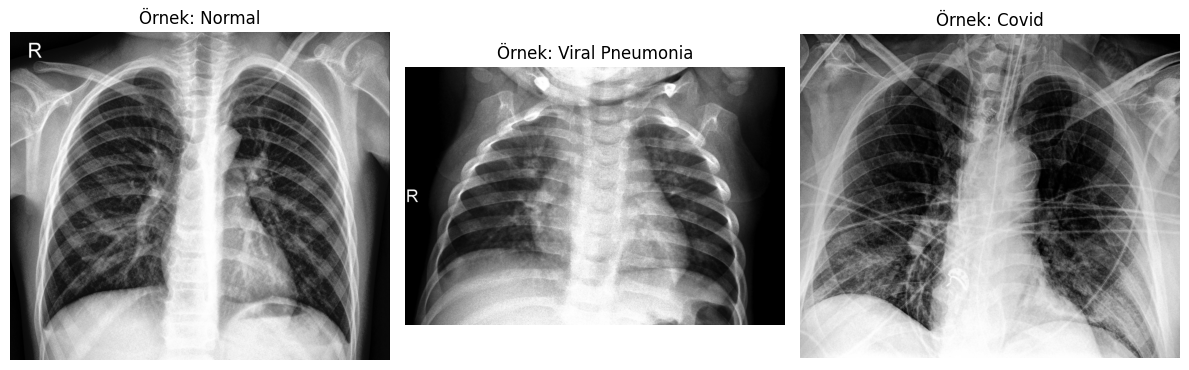

2. Aşama tamamlandı: Dosya yolları bulundu ve örnek resimler ekrana yansıtıldı!


In [4]:
# 2. AŞAMA: Dosya Yollarının Belirlenmesi ve Görselleştirme

import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# 1. Kaggle klasörleri arasında gezinip 'train' ve 'test' dosyalarını otomatik bulalım
train_dir = ""
test_dir = ""

for root, dirs, files in os.walk('/kaggle/input'):
    if 'train' in dirs and 'test' in dirs:
        train_dir = os.path.join(root, 'train')
        test_dir = os.path.join(root, 'test')
        break

print("Eğitim verilerinin yolu:", train_dir)
print("Test verilerinin yolu:", test_dir)

# 2. Veri setindeki hastalık sınıflarını (Covid, Normal vb.) bulalım
siniflar = os.listdir(train_dir)
print("Tespit Edilen Hastalık Sınıfları:", siniflar)

# 3. Her sınıftan birer tane röntgen görüntüsünü ekrana çizdirelim
plt.figure(figsize=(12, 5))
for i, sinif in enumerate(siniflar):
    sinif_yolu = os.path.join(train_dir, sinif)
    resim_isimleri = os.listdir(sinif_yolu)
    
    if len(resim_isimleri) > 0:
        # Klasördeki ilk resmi seç
        ilk_resim_adi = resim_isimleri[0]
        resim_yolu = os.path.join(sinif_yolu, ilk_resim_adi)
        
        # Resmi ekrana yansıt
        plt.subplot(1, len(siniflar), i + 1)
        resim = mpimg.imread(resim_yolu)
        plt.imshow(resim, cmap='gray') # Röntgen resimleri için gri tonlama
        plt.title(f"Örnek: {sinif}")
        plt.axis('off')

plt.tight_layout()
plt.show()

print("2. Aşama tamamlandı: Dosya yolları bulundu ve örnek resimler ekrana yansıtıldı!")

In [5]:
# 3. AŞAMA: Veri Ön İşleme (Preprocessing) ve Çoğaltma (Data Augmentation)

from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Kullanacağımız hazır modeller genelde 224x224 piksel çözünürlük bekler
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Eğitim verisini çoğaltma (Augmentation) ve Validation (Doğrulama) ayırma
train_datagen = ImageDataGenerator(
    rescale=1./255,          # Pikselleri 0-1 arasına sıkıştır (Yapay zeka bu aralığı daha kolay anlar)
    rotation_range=20,       # Resimleri %20'ye kadar döndür
    zoom_range=0.15,         # Hafifçe yakınlaştır
    horizontal_flip=True,    # Yatayda çevir (Model sadece sağa/sola bakan ciğerleri ezberlemesin)
    validation_split=0.2     # Eğitim verisinin %20'sini deneme sınavı (Validation) için ayırıyoruz
)

# Test verisinde resim çevirme/yakınlaştırma yapılmaz, sadece pikselleri normalize ediyoruz
test_datagen = ImageDataGenerator(rescale=1./255)

print("Eğitim (Train) seti hazırlanıyor...")
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'        # %80'lik ana eğitim kısmı
)

print("\nDoğrulama (Validation) seti hazırlanıyor...")
validation_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'      # Eğitim içinden ayırdığımız %20'lik deneme sınavı kısmı
)

print("\nTest seti hazırlanıyor...")
test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False            # Testin sırasını bozmuyoruz ki sonuçları doğru eşleştirelim
)

print("\n3. Aşama tamamlandı: Veriler modele girmeye hazır!")

Eğitim (Train) seti hazırlanıyor...
Found 201 images belonging to 3 classes.

Doğrulama (Validation) seti hazırlanıyor...
Found 50 images belonging to 3 classes.

Test seti hazırlanıyor...
Found 66 images belonging to 3 classes.

3. Aşama tamamlandı: Veriler modele girmeye hazır!


In [6]:
# 4. AŞAMA: Yapay Zeka Modelinin Oluşturulması (Transfer Öğrenme - DenseNet121)

from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout

# 1. Hazır, önceden eğitilmiş DenseNet121 modelini çağırıyoruz
# include_top=False: Modelin orijinal sınıflandırma kısmını atıyoruz, sadece "özellik çıkaran" kısmını alıyoruz.
base_model = DenseNet121(
    weights='imagenet', 
    include_top=False, 
    input_shape=(224, 224, 3)
)

# Hazır modelin daha önce milyonlarca resimden öğrendiği yetenekleri bozmamak için katmanlarını donduruyoruz
base_model.trainable = False

# 2. Kendi Karar Mekanizmamızı (Sınıflandırıcı) Ekliyoruz
model = Sequential([
    base_model,                                 # DenseNet'in güçlü görme yeteneği
    GlobalAveragePooling2D(),                   # Çıkarılan karmaşık özellikleri düzleştirip özetler
    Dense(128, activation='relu'),              # Karar vermek için ekstra nöronlar ekliyoruz
    Dropout(0.3),                               # Modelin ezber (overfitting) yapmasını engellemek için %30 rastgele kapatma
    Dense(train_generator.num_classes, activation='softmax') # Sonuç katmanı (Sınıf sayısı kadar çıkış verir)
])

# 3. Modelin Derlenmesi (Hata hesaplama ve optimizasyon yöntemi)
model.compile(
    optimizer='adam', 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)

# Modelin yapısını ve katmanlarını ekrana yazdırıyoruz
model.summary()

print("\n4. Aşama tamamlandı: DenseNet121 tabanlı model başarıyla oluşturuldu ve derlendi!")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,169,091 (27.35 MB)

 Trainable params: 131,587 (514.01 KB)

 Non-trainable params: 7,037,504 (26.85 MB)


4. Aşama tamamlandı: DenseNet121 tabanlı model başarıyla oluşturuldu ve derlendi!


In [12]:
# 5. AŞAMA: Modelin Eğitilmesi (Training)

# Eğitimin kaç tur (döngü) süreceğini belirliyoruz
EPOCH_SAYISI = 98

print(f"Eğitim başlıyor... Bu işlem toplam {EPOCH_SAYISI} tur (epoch) sürecek.")
print("Her turda model resimleri inceleyecek ve ayırdığımız %20'lik doğrulama (validation) setiyle kendini test edecek.\n")

# Modeli eğitiyoruz ve bu sürecin geçmişini (history) 6. aşamadaki grafikler için kaydediyoruz
history = model.fit(
    train_generator,
    epochs=EPOCH_SAYISI,
    validation_data=validation_generator
)

print("\n5. Aşama tamamlandı: Model eğitimi başarıyla bitti!")

Eğitim başlıyor... Bu işlem toplam 98 tur (epoch) sürecek.
Her turda model resimleri inceleyecek ve ayırdığımız %20'lik doğrulama (validation) setiyle kendini test edecek.

Epoch 1/98
7/7 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.9950 - loss: 0.0158 - val_accuracy: 0.9200 - val_loss: 0.4060
Epoch 2/98
7/7 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 1.0000 - loss: 0.0043 - val_accuracy: 0.8600 - val_loss: 0.5091
Epoch 3/98
7/7 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 1.0000 - loss: 0.0051 - val_accuracy: 0.8600 - val_loss: 0.5275
Epoch 4/98
7/7 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.9900 - loss: 0.0191 - val_accuracy: 0.8800 - val_loss: 0.4476
Epoch 5/98
7/7 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.9950 - loss: 0.0309 - val_accuracy: 0.8800 - val_loss: 0.4895
Epoch 6/98
7/7 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.9900 - loss: 0.0246 - val_accuracy: 0.8600 - val_loss: 0.5618
Epoch 7/98
7/7 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.9801 - loss: 0.0393 - val_a

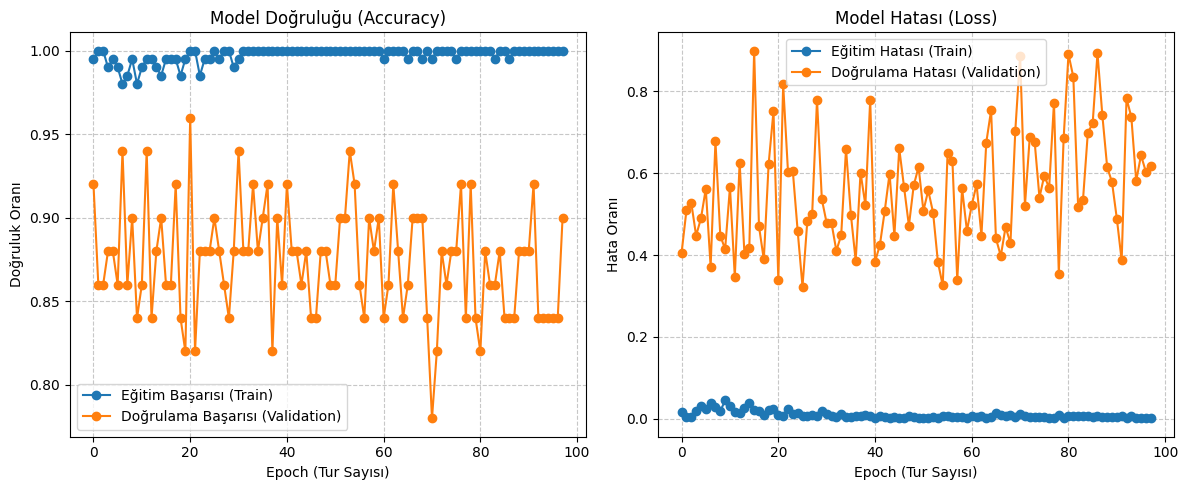

Model, hiç görmediği 'test' klasöründeki resimlerle nihai sınava sokuluyor...

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 194ms/step - accuracy: 0.9545 - loss: 0.1856

--- NİHAİ SONUÇ ---
Test Başarısı (Accuracy): %95.45
Test Hatası (Loss): 0.1856

6. Aşama tamamlandı: Modelin performansı ölçüldü ve grafikleri çizildi!


In [13]:
# 6. AŞAMA: Modelin Test Edilmesi ve Başarısının Ölçülmesi

import matplotlib.pyplot as plt

# 1. Eğitim Sürecinin Grafiklerini Çizdirelim
plt.figure(figsize=(12, 5))

# Doğruluk (Accuracy) Grafiği
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Eğitim Başarısı (Train)', marker='o')
plt.plot(history.history['val_accuracy'], label='Doğrulama Başarısı (Validation)', marker='o')
plt.title('Model Doğruluğu (Accuracy)')
plt.xlabel('Epoch (Tur Sayısı)')
plt.ylabel('Doğruluk Oranı')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

# Hata (Loss) Grafiği
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Eğitim Hatası (Train)', marker='o')
plt.plot(history.history['val_loss'], label='Doğrulama Hatası (Validation)', marker='o')
plt.title('Model Hatası (Loss)')
plt.xlabel('Epoch (Tur Sayısı)')
plt.ylabel('Hata Oranı')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# 2. Test Seti ile Nihai Sınav
print("Model, hiç görmediği 'test' klasöründeki resimlerle nihai sınava sokuluyor...\n")

# test_generator'ı sıfırlayalım ki baştan başlasın
test_generator.reset() 
test_loss, test_acc = model.evaluate(test_generator)

print(f"\n--- NİHAİ SONUÇ ---")
print(f"Test Başarısı (Accuracy): %{test_acc * 100:.2f}")
print(f"Test Hatası (Loss): {test_loss:.4f}")
print("\n6. Aşama tamamlandı: Modelin performansı ölçüldü ve grafikleri çizildi!")

Test seti üzerinde detaylı tahminler yapılıyor...

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 190ms/step

--- DETAYLI SINIFLANDIRMA RAPORU ---
                 precision    recall  f1-score   support

          Covid       1.00      0.96      0.98        26
         Normal       0.95      0.90      0.92        20
Viral Pneumonia       0.91      1.00      0.95        20

       accuracy                           0.95        66
      macro avg       0.95      0.95      0.95        66
   weighted avg       0.96      0.95      0.95        66



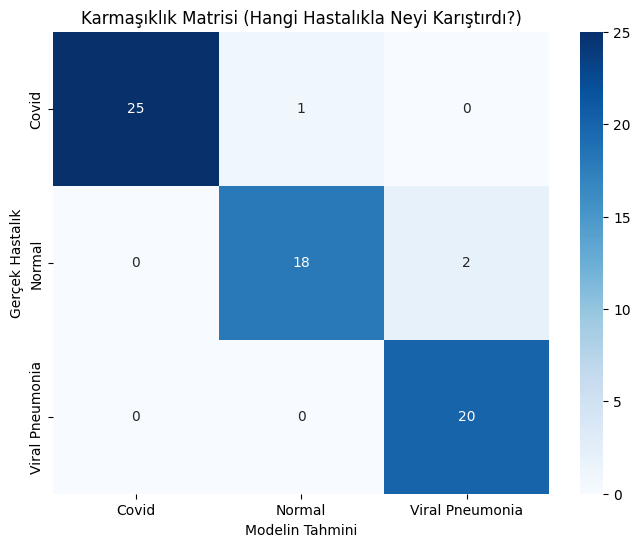

In [15]:
# 6. AŞAMAYA EK: Detaylı Sınıf İstatistikleri ve Karmaşıklık Matrisi

import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Model test veri setindeki tüm resimleri tek tek tahmin etsin
print("Test seti üzerinde detaylı tahminler yapılıyor...\n")
test_generator.reset() # Veri sırasını başa alıyoruz ki etiketlerle eşleşsin
tahmin_skorlari = model.predict(test_generator)
tahmin_edilen_siniflar = np.argmax(tahmin_skorlari, axis=1)

# 2. Gerçek etiketleri (cevap anahtarını) ve sınıf isimlerini alalım
gercek_siniflar = test_generator.classes
sinif_isimleri = list(test_generator.class_indices.keys())

# 3. Hocanızın gösterdiği DETAYLI SINIFLANDIRMA RAPORU
print("\n--- DETAYLI SINIFLANDIRMA RAPORU ---")
print(classification_report(gercek_siniflar, tahmin_edilen_siniflar, target_names=sinif_isimleri))

# 4. Karmaşıklık Matrisi (Confusion Matrix) Görselleştirmesi
cm = confusion_matrix(gercek_siniflar, tahmin_edilen_siniflar)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=sinif_isimleri, yticklabels=sinif_isimleri)
plt.title('Karmaşıklık Matrisi (Hangi Hastalıkla Neyi Karıştırdı?)')
plt.xlabel('Modelin Tahmini')
plt.ylabel('Gerçek Hastalık')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step


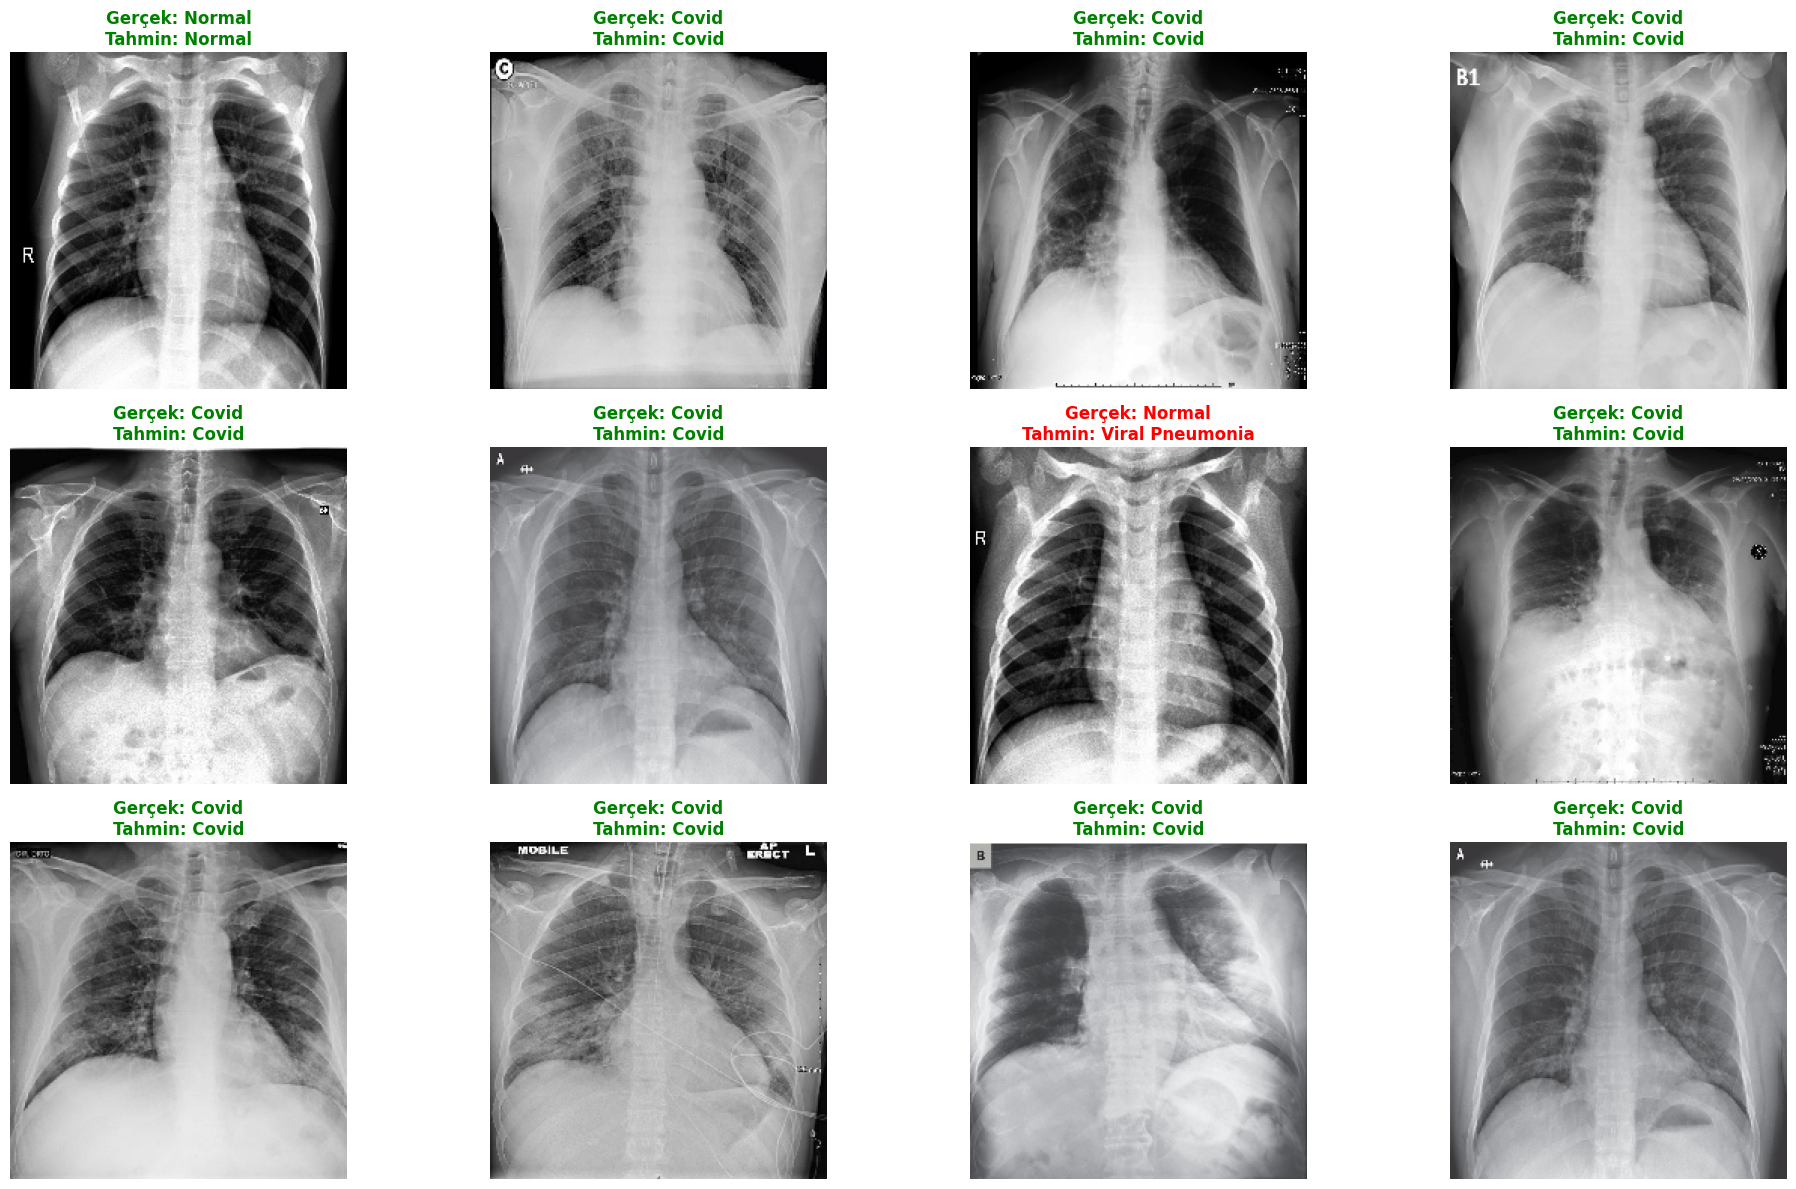

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import random

# Jeneratörü başa sarıyoruz ki tam dolu bir resim paketi gelsin
test_generator.reset() 
test_resimleri, test_etiketleri = next(test_generator)
sinif_isimleri = list(test_generator.class_indices.keys())

# Yapay zeka teşhis koyuyor
tahmin_skorlari = model.predict(test_resimleri)
tahmin_edilen_siniflar = np.argmax(tahmin_skorlari, axis=1)
gercek_siniflar = np.argmax(test_etiketleri, axis=1)

# Eğer pakette 12'den az resim varsa hata vermemesi için güvenli sayıyı alıyoruz
gosterilecek_sayi = min(12, len(test_resimleri))

plt.figure(figsize=(20, 12))
rastgele_indeksler = random.sample(range(len(test_resimleri)), gosterilecek_sayi)

for i, idx in enumerate(rastgele_indeksler):
    plt.subplot(3, 4, i + 1)
    resim = test_resimleri[idx]
    
    plt.imshow(resim)
    plt.axis('off')
    
    gercek_isim = sinif_isimleri[gercek_siniflar[idx]]
    tahmin_isim = sinif_isimleri[tahmin_edilen_siniflar[idx]]
    
    renk = 'green' if gercek_isim == tahmin_isim else 'red'
    plt.title(f"Gerçek: {gercek_isim}\nTahmin: {tahmin_isim}", color=renk, fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

In [20]:
# Eğitilen modelin beynini (ağırlıklarını) kalıcı olarak kaydediyoruz
model.save('covid19_densenet121_model.h5')
print("Yapay zeka başarıyla dosyaya kaydedildi!")

Yapay zeka başarıyla dosyaya kaydedildi!
